# Exact-Hessian nonlinear least squares

For a mean function $\mu_i(b)$ and residual $r_i=\mu_i(b)-y_i$,
$$f(b)=\frac{r^Tr}{2n},\qquad g(b)=J^Tr/n,\qquad
 H(b)=\frac{J^TJ+\sum_i r_i\nabla^2\mu_i(b)}n.$$
The residual-curvature term can make the Hessian indefinite away from a solution.
This notebook compares the exponential-mean estimator with the generic NLS
callback interface, uses multiple starts, and checks the fit against SciPy's
specialized least-squares solver.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1007)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from scipy.optimize import least_squares
from galahad_econometrics import ExponentialNLS, NLS, check_derivatives

n, p = 1400, 3
X = rng.normal(size=(n, p))
D = np.column_stack([np.ones(n), X])
beta = np.array([.2, .5, -.4, .2])
y = np.exp(D @ beta) + .15*rng.normal(size=n)
model = ExponentialNLS(X, y)

generic = NLS(y, mean=lambda b: np.exp(D @ b),
              jac=lambda b: np.exp(D @ b)[:, None]*D,
              weighted_hess=lambda b, r: D.T @ ((r*np.exp(D @ b))[:, None]*D),
              x0=np.zeros(p+1))
probe = .2*beta
assert max(check_derivatives(generic, probe).values()) < 1e-6
assert np.allclose(generic.hess(probe), model.hess(probe))

## Inspect the curvature

The generic callback returns the weighted sum of mean Hessians as a `p × p`
matrix, avoiding an `n × p × p` tensor. The table compares exact and Gauss–Newton
curvature at named multiples of the true coefficient vector. A negative minimum
eigenvalue indicates a nonconvex local quadratic model at that point.

In [3]:
curvature_rows = []
for multiple in [-1., 0., .2, 1., 2.]:
    point = multiple*beta
    J = np.exp(D @ point)[:, None]*D
    gn = J.T @ J/n
    exact = model.hess(point)
    curvature_rows.append({"truth multiple": multiple,
                           "exact min eigenvalue": np.linalg.eigvalsh(exact).min(),
                           "Gauss-Newton min eigenvalue": np.linalg.eigvalsh(gn).min(),
                           "residual-curvature norm": np.linalg.norm(exact-gn)})
pd.DataFrame(curvature_rows).set_index("truth multiple")

,exact min eigenvalue,Gauss-Newton min eigenvalue,residual-curvature norm
truth multiple,,,
-1,-0.006766,0.49198,5.0581
0,-0.93875,0.94556,2.0609
0.2,-0.90997,0.8448,2.4849
1,0.98075,0.98034,0.095854
2,6.9,4.4068,330.74


## Multiple starting points

Each named solver/start pair is retained. Parameter agreement is checked against
an independently specified SciPy residual problem. The convergence traces contain
candidate evaluations, including rejected points. Their wall-time axis includes
logging overhead and is separate from any clean performance benchmark.

In [4]:
reference = least_squares(lambda b: np.exp(D @ b)-y, np.zeros(p+1),
                          jac=lambda b: np.exp(D @ b)[:, None]*D,
                          ftol=1e-12, xtol=1e-12, gtol=1e-12)
fref = .5*np.mean(reference.fun**2)
starts = {"zero": np.zeros(p+1), "large": 3*beta, "opposite": -4*beta}
results, rows = {}, []
for start_name, start in starts.items():
    for solver in ["tru", "arc"]:
        fit = model.fit(solver=solver, x0=start, trace=True)
        result = fit.optimization
        assert fit.success, (start_name, solver, result.message)
        assert np.max(np.abs(fit.params-reference.x)) < 2e-6
        results[start_name, solver] = fit
        rows.append({"start": start_name, "solver": solver.upper(), "native status": result.status,
                     "objective gap": result.fun-fref, "scaled gradient": result.optimality,
                     "coefficient error norm": np.linalg.norm(fit.params-reference.x)})
pd.DataFrame(rows).set_index(["start", "solver"])

native status  objective gap  scaled gradient  \
start    solver                                                  
zero     TRU                 0              0       1.0438e-11   
         ARC                 0              0       7.8599e-15   
large    TRU                 0              0        1.491e-15   
         ARC                 0              0        5.618e-16   
opposite TRU                 0     1.7347e-18       2.5949e-09   
         ARC                 0              0       8.0793e-14   

                 coefficient error norm  
start    solver                          
zero     TRU                 1.2032e-10  
         ARC                 1.2092e-10  
large    TRU                 1.2092e-10  
         ARC                 1.2092e-10  
opposite TRU                 1.8004e-09  
         ARC                 1.2097e-10

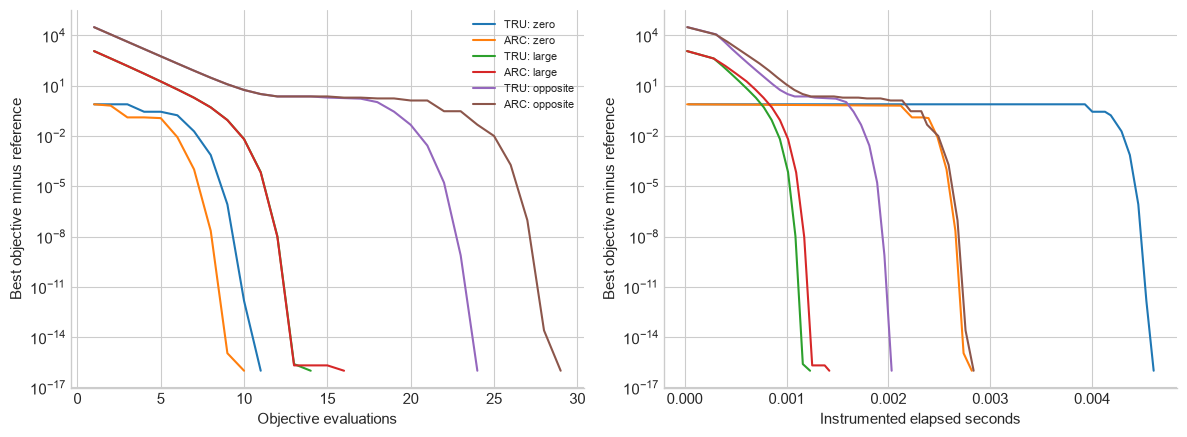

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (start, solver), fit in results.items():
    history = fit.optimization.history
    values = np.array([h.objective for h in history])
    gap = np.maximum(np.minimum.accumulate(values)-fref, 1e-16)
    label = f"{solver.upper()}: {start}"
    axes[0].semilogy(np.arange(1, len(history)+1), gap, label=label)
    axes[1].semilogy([h.seconds for h in history], gap, label=label)
axes[0].set(xlabel="Objective evaluations", ylabel="Best objective minus reference")
axes[1].set(xlabel="Instrumented elapsed seconds", ylabel="Best objective minus reference")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Inference and conditional-mean recovery

The generic NLS interface uses the exact observed Hessian as the sandwich bread.
Covariance is computed only for a fit that passes the numerical accuracy check.
The coefficient table compares sample solutions separately from the DGP truth.

In [6]:
generic_fit = generic.fit(solver="arc", cov_type="HC1")
assert np.max(np.abs(generic_fit.params-reference.x)) < 2e-6
pd.DataFrame({"truth": beta, "SciPy sample solution": reference.x,
              "generic NLS ARC": generic_fit.params, "HC1 SE": generic_fit.bse},
             index=["intercept", "x1", "x2", "x3"])

,truth,SciPy sample solution,generic NLS ARC,HC1 SE
intercept,0.2,0.19727,0.19727,0.0035115
x1,0.5,0.50266,0.50266,0.0021808
x2,-0.4,-0.40468,-0.40468,0.0020576
x3,0.2,0.20076,0.20076,0.0019984


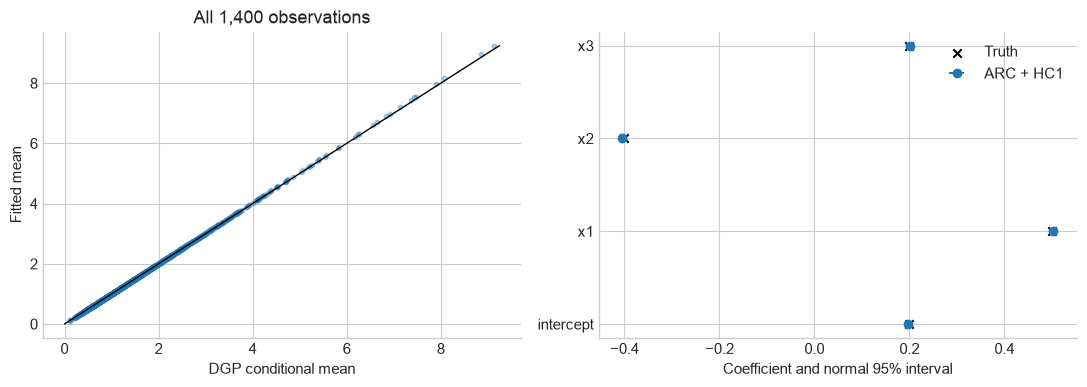

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
truth_mean = np.exp(D @ beta)
axes[0].scatter(truth_mean, generic_fit.fitted_values, s=10, alpha=.35)
limit = max(truth_mean.max(), generic_fit.fitted_values.max())
axes[0].plot([0, limit], [0, limit], color="black", linewidth=1)
axes[0].set(xlabel="DGP conditional mean", ylabel="Fitted mean", title="All 1,400 observations")
positions = np.arange(p+1)
axes[1].errorbar(generic_fit.params, positions, xerr=1.96*generic_fit.bse, fmt="o", label="ARC + HC1")
axes[1].scatter(beta, positions, marker="x", color="black", label="Truth")
axes[1].set_yticks(positions, ["intercept", "x1", "x2", "x3"])
axes[1].set_xlabel("Coefficient and normal 95% interval")
axes[1].legend()
fig.tight_layout()
plt.show()

Matching all three starts on this DGP is evidence about these sample problems,
not a global-convergence theorem for NLS. In structural estimation, starts,
identification, parameterization and domain restrictions remain substantive
parts of the specification.